# Session 15 lecture: Capstone studio: combining evidence

<p class="lead">
A capstone asks you to do what an analyst does at work: take evidence from several parts of an organisation, keep each piece honest, and help a leadership team choose one action. This lecture shows how to record evidence so others can check it, how to put different datasets side by side without inventing links between them, how to weigh options openly, and how to package your checks so a reviewer can trust the result.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/15_capstone_studio_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 14 lecture](14_dashboards_storytelling_lecture.md). Write short answers; we discuss them together.

1. What is the difference between an **exploratory** chart and an **explanatory** chart? Which one belongs in front of a leadership team?
2. Rewrite the chart title "Sales by month, 2025" as a title that states the main message.
3. A story can follow **situation → complication → resolution**. What goes in each part?
4. On a dashboard, where should the single most important number go, and why?
5. Give one way an annotation helps a reader and one way it can mislead.
6. In the Challenger case, what was missing from the charts the engineers used, and why did it matter for the decision?

---

## What you will be able to explain

1. What a **capstone** must show: one decision, evidence from at least three business domains, and all five domains covered in your portfolio.
2. How an **evidence register** records each claim with its source, metric definition, grain, period, value, check and limitation.
3. Why you **aggregate inside each dataset first** and never join rows across unrelated datasets.
4. How to put several monthly series **side by side** on a common calendar without claiming they are linked.
5. Why **co-movement** between series from separate contexts is not evidence of a link.
6. How to build a **trade-off table** with explicit weights, and test whether the ranking survives a change of weights.
7. What goes into a **validation pack**: data versions, reconciliations and a reproducible notebook.
8. How a **peer review** checks one critical number and one competing explanation.

This lecture uses ideas from almost every earlier session: grain ([Session 2](02_data_and_grain_lecture.md)), joins and cardinality ([Session 3](03_cleaning_and_preparing_lecture.md)), weighted rates ([Session 5](05_metrics_and_kpis_lecture.md)), correlation and confounding ([Session 8](08_correlation_and_regression_lecture.md)) and the four business cases. In the **Lab** you build your own register, checks and trade-off table, then repair a flawed capstone draft.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

This lecture uses all five course datasets, so there are five setup cells. Run them in order, then the cell after them, which loads the tables.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [3]:
# Finance data setup (synthetic). Run this cell first.
# Downloads the course's synthetic finance data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

FINANCE_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/finance-v1/"
FINANCE_SHA256 = {
    "finance_actuals.csv": "3aeb2773990f86c21a1536b8854d7290794315e8bc872420c2e5df77151ac7fd",
    "finance_budget.csv": "238dbec8e7e80a61068c12c48280ff4f9de91198879ee295366774f530efad60",
}
FINANCE_DIR = os.environ.get("COURSE_FINANCE_DIR", "")


def load_finance(name):
    """Load one finance-v1 file: 'finance_actuals.csv' or 'finance_budget.csv'."""
    if FINANCE_DIR:
        with open(os.path.join(FINANCE_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(FINANCE_URL + name).read()
    if hashlib.sha256(data).hexdigest() != FINANCE_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["month"], keep_default_na=False,
                       na_values={"amount": [""], "budget": [""]})


print("Finance setup complete.")

Finance setup complete.


In [4]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [5]:
# HR data setup (synthetic). Run this cell first.
# Downloads the course's synthetic workforce data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

HR_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/hr-v1/"
HR_SHA256 = {
    "employees.csv": "7d59a66675d53b7d6de8cce6a4d3369ddd6268e51913e86f30e9560c019342a9",
    "department_history.csv": "12e6524a7838e9d5426c2bef116769ad850d5eaf11e10958a4e4ae13d21dca36",
    "recruitment.csv": "3a6c2046fd5cbb4a07d435f50e3d10e5df160314decd1e651718a5d0bd7fbc05",
}
HR_DATES = {
    "employees.csv": ["hire_date", "exit_date"],
    "department_history.csv": ["effective_from", "effective_to"],
    "recruitment.csv": ["opened_date", "offer_accepted_date", "hire_date"],
}
HR_DIR = os.environ.get("COURSE_HR_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_hr(name):
    """Load one hr-v1 file: 'employees.csv', 'department_history.csv' or 'recruitment.csv'."""
    if HR_DIR:
        with open(os.path.join(HR_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(HR_URL + name).read()
    if hashlib.sha256(data).hexdigest() != HR_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=HR_DATES[name])


print("HR setup complete.")

HR setup complete.


In [6]:
import datetime
import platform

import numpy as np

ONE_DAY = datetime.timedelta(days=1)
MONTHS = pd.date_range("2025-01-01", "2025-12-01", freq="MS")   # the common calendar: 2025 only

orders = load_orders()
marketing = load_marketing("marketing_daily.csv")
actuals = load_finance("finance_actuals.csv")
budget = load_finance("finance_budget.csv")
shipments = load_shipments()
employees = load_hr("employees.csv")
history = load_hr("department_history.csv")

pd.DataFrame({
    "rows": [len(orders), len(marketing), len(actuals), len(budget), len(shipments), len(employees), len(history)],
}, index=["Superstore order lines", "Marketing campaign-days", "Finance postings", "Finance budget cells",
          "Shipments", "Employees", "Department intervals"])

,rows
Superstore order lines,6815
Marketing campaign-days,2555
Finance postings,1378
Finance budget cells,432
Shipments,5893
Employees,520
Department intervals,543


---

## Part 1: What a capstone must show

A capstone is not a longer lab. It is **one decision**, argued with evidence a sceptical reader can check.

| Requirement | What it means in practice |
|---|---|
| **One decision** | A single, bounded choice for a named stakeholder: "which improvement to fund next quarter", not "insights about the business" |
| **Evidence from at least three domains** | At least three of retail, finance, operations, marketing and HR each contribute a finding that bears on the choice |
| **All five domains in your portfolio** | Your lab portfolio already covers all five. The two domains you do not use get a short **screening note**: why they were checked and left out |
| **Metric contracts** | Every number states its grain, period, filters, numerator, denominator and treatment of missing values |
| **Validation pack** | Data versions, reconciliations, a corrected bug and a notebook that reruns from top to bottom |
| **Trade-offs and limits** | Options compared openly, a recommendation with an owner and a monitoring measure, and what the data cannot show |

> **About the data: five separate contexts**
>
> The five datasets are **not one company**. Superstore is Tableau's **fictitious** sample store, with amounts in the source's monetary units. The marketing, finance, operations and HR files were each generated **separately** by the course for fictional organisations, with amounts in neutral **currency units**. They share no customers, orders, employees or keys.
>
> For the capstone we use a **teaching frame**: imagine one leadership team that receives five departmental evidence packs. That frame lets you practise weighing evidence across domains. It does **not** make the datasets one company, and it does not allow you to link their rows or explain one with another.

| Dataset | Context | Units | One row is | Period used here |
|---|---|---|---|---|
| Superstore | Tableau's fictitious sample store | Source monetary units | One order line | Orders placed in 2025 |
| marketing-v1 | Synthetic, fictional campaigns | Currency units | One campaign on one day | 2025 |
| finance-v1 | Synthetic, fictional expense view | Currency units | One posting / one budget cell | 2025 |
| operations-v1 | Synthetic, fictional retailer's shipments | Shipments | One shipment | Promised in 2025, cutoff 2025-12-31 |
| hr-v1 | Synthetic, fictional workforce | Employees | One employee / one department interval | 2025, cutoff 2025-12-31 |

> **Check your understanding 1**
>
> A classmate writes: "Superstore sales rose in December, and the HR data show Operations shrank, so the warehouse could not keep up." Name two separate problems with this sentence.

---

## Part 2: The decision for this lecture's worked case

> *Chief operating officer (teaching frame): "We can fund one improvement next quarter. I have four proposals on my desk. Tell me which one the evidence supports best, how sure you are, and what you would watch afterwards."*

| Option | Proposal | Main evidence domain |
|---|---|---|
| **A** | Review delivery carriers and peak-season capacity | Operations |
| **B** | A retention programme for the Operations team | HR |
| **C** | Move budget away from campaigns that return less than they cost | Marketing |
| **D** | Renegotiate the software contracts that are over budget | Finance |

Retail is used as **context** about the demand pattern of a store over the year, not as evidence for any one option. Each option rests on evidence from **its own** dataset. That is what lets you compare them without false links.

---

## Part 3: Build each domain's evidence separately

The first rule of combining evidence: **aggregate inside each dataset first, under its own contract**. Each function below produces a monthly table for 2025 from one dataset and nothing else. You have seen every calculation before, in the session named in the comment.

In [7]:
def retail_monthly(orders):
    """Superstore, orders placed in 2025: Sales (sum of order lines) and distinct orders per month. Session 7."""
    r = orders[orders["order_date"].dt.year == 2025]
    return r.groupby("order_month").agg(sales=("sales", "sum"), orders=("order_id", "nunique")).reindex(MONTHS)


def marketing_monthly(daily):
    """marketing-v1: spend, attributed revenue and conversions per month (sums; rates come later). Session 12."""
    month = daily["date"].dt.to_period("M").dt.to_timestamp()
    m = daily.groupby(month).agg(spend=("spend", "sum"), attributed_revenue=("attributed_revenue", "sum"),
                                 conversions=("conversions", "sum"))
    return m.reindex(MONTHS)


def finance_cells(actuals, budget):
    """finance-v1: aggregate postings to (month, department, account) FIRST, then outer-join the budget. Session 10."""
    keys = ["month", "department", "account"]
    a = actuals.groupby(keys, as_index=False)["amount"].sum().rename(columns={"amount": "actual"})
    return a.merge(budget[keys + ["budget"]], on=keys, how="outer").fillna({"actual": 0.0})


def finance_monthly(cells):
    """Comparable scope only (known budget): actual, budget and variance per month."""
    known = cells[cells["budget"].notna()]
    m = known.groupby("month")[["actual", "budget"]].sum()
    m["variance"] = m["actual"] - m["budget"]
    return m.reindex(MONTHS)


def service_population(shipments):
    """operations-v1: label each shipment at the cutoff. Session 11."""
    s = shipments.copy()
    s["population"] = np.select(
        [s["status"] == "canceled", s["promised_date"].isna(), s["promised_date"] > CUTOFF],
        ["canceled", "unknown promise", "not yet due"], default="due")
    s["on_time"] = s["delivered_date"].notna() & (s["delivered_date"] <= s["promised_date"])
    return s


def operations_monthly(s):
    """On-time rate by promised month: on-time due shipments / ALL due shipments (pending ones count as failures)."""
    due = s[s["population"] == "due"]
    month = due["promised_date"].dt.to_period("M").dt.to_timestamp()
    m = due.groupby(month).agg(due=("on_time", "size"), on_time=("on_time", "sum"))
    m["on_time_rate"] = m["on_time"] / m["due"].where(m["due"] > 0)
    return m.reindex(MONTHS)


def active_on(table, day, start="effective_from", end="effective_to"):
    """Rows whose interval [start, end) contains `day`. Session 13."""
    day = pd.Timestamp(day)
    return int(((table[start] <= day) & (table[end].isna() | (table[end] > day))).sum())


def hr_department_monthly(history, department):
    """hr-v1: opening, exits and closing headcount of one department per month (exits = leaving the company)."""
    h = history.sort_values(["employee_id", "effective_from"]).copy()
    h["last_interval"] = ~h.duplicated("employee_id", keep="last")
    d = h[h["department"] == department]
    rows = []
    for m in MONTHS:
        end = m + pd.offsets.MonthEnd(0)
        rows.append({"opening": active_on(d, m - ONE_DAY),
                     "exits": int((d["last_interval"] & d["effective_to"].between(m, end)).sum()),
                     "closing": active_on(d, end)})
    return pd.DataFrame(rows, index=MONTHS)


retail_m = retail_monthly(orders)
marketing_m = marketing_monthly(marketing)
cells = finance_cells(actuals, budget)
finance_m = finance_monthly(cells)
s = service_population(shipments)
operations_m = operations_monthly(s)
hr_ops_m = hr_department_monthly(history, "Operations")
print("Five monthly tables built, one per dataset, each with", len(MONTHS), "months.")

Five monthly tables built, one per dataset, each with 12 months.


Each table has its own **grain** (one row per month of 2025), its own **units** and its own **contract**. None of them has touched another dataset. Look at one of them to check it is what you expect:

In [8]:
operations_m.assign(on_time_rate=operations_m["on_time_rate"].map("{:.1%}".format))

,due,on_time,on_time_rate
2025-01-01,372,324,87.1%
2025-02-01,415,362,87.2%
2025-03-01,441,391,88.7%
2025-04-01,415,372,89.6%
2025-05-01,423,368,87.0%
2025-06-01,434,373,85.9%
2025-07-01,470,413,87.9%
2025-08-01,462,401,86.8%
2025-09-01,490,426,86.9%
2025-10-01,403,359,89.1%


---

## Part 4: The evidence register

An **evidence register** is a table with one row per claim you intend to make. It is the backbone of the capstone: every sentence in your briefing should point to a row, and every row should say how it was checked and what it cannot show.

| Column | What to write | Example |
|---|---|---|
| **Claim** | One sentence a manager could repeat | "On-time delivery collapsed in December" |
| **Source** | Dataset and version | operations-v1 `shipments.csv` |
| **Metric definition** | Numerator, denominator, filters | On-time due shipments ÷ all due shipments |
| **Grain** | What one counted unit is | Shipment, by promised month |
| **Period** | Dates and cutoff | December 2025 vs Jan–Oct 2025; cutoff 2025-12-31 |
| **Value** | The number, with units, from code | Filled in by the cell below, never typed |
| **Check performed** | How you know it is right | Populations add back to all shipments |
| **Limitation** | What it cannot show | Descriptive; does not show the cause of the drop |

The cell below computes one value per domain and writes the register. Every value comes from the tables in Part 3.

In [9]:
# Values for the register, each from its own dataset.
retail_total = retail_m["sales"].sum()
retail_q4_share = retail_m.loc["2025-10-01":, "sales"].sum() / retail_total

campaigns = marketing.groupby("campaign_id")[["spend", "attributed_revenue"]].sum()
campaigns["roas"] = campaigns["attributed_revenue"] / campaigns["spend"].where(campaigns["spend"] > 0)
roas_all = campaigns["attributed_revenue"].sum() / campaigns["spend"].sum()
below_one = campaigns[campaigns["roas"] < 1]

software = cells[(cells["department"] == "Technology") & (cells["account"] == "Software subscriptions")
                 & cells["budget"].notna()]
software_var_pct = (software["actual"].sum() - software["budget"].sum()) / software["budget"].sum()

dec = operations_m.loc["2025-12-01"]
jan_oct = operations_m.loc[:"2025-10-01"]
jan_oct_rate = jan_oct["on_time"].sum() / jan_oct["due"].sum()

ops_avg_headcount = ((hr_ops_m["opening"] + hr_ops_m["closing"]) / 2).mean()
ops_turnover = hr_ops_m["exits"].sum() / ops_avg_headcount

register = pd.DataFrame([
    {"claim": "Store sales are concentrated in the last quarter (context)",
     "source": "Superstore (Tableau sample)", "metric": "Oct-Dec Sales / 2025 Sales",
     "grain": "Order line, by order month", "period": "Orders placed in 2025",
     "value": f"{retail_q4_share:.0%} of {retail_total:,.0f} source units",
     "check": "Monthly sums equal the annual total",
     "limitation": "Fictitious sample store; a different context from the other four"},
    {"claim": "On-time delivery fell sharply in December",
     "source": "operations-v1 shipments", "metric": "On-time due / all due shipments",
     "grain": "Shipment, by promised month", "period": "Dec vs Jan-Oct 2025, cutoff 31 Dec",
     "value": f"{dec['on_time_rate']:.1%} of {int(dec['due'])} vs {jan_oct_rate:.1%}",
     "check": "Populations add back to all shipments",
     "limitation": "Descriptive; does not show why it fell"},
    {"claim": "The Operations team had high turnover in 2025",
     "source": "hr-v1 department history", "metric": "Exits / mean monthly average headcount",
     "grain": "Department interval, monthly", "period": "2025, cutoff 31 Dec",
     "value": f"{ops_turnover:.0%} ({hr_ops_m['exits'].sum()} exits)",
     "check": "Department exits add up to company exits",
     "limitation": "Cannot show causes or anyone's performance"},
    {"claim": "Some campaigns return less attributed revenue than they cost",
     "source": "marketing-v1 daily", "metric": "Attributed revenue / spend (ratio of sums)",
     "grain": "Campaign-day, summed by campaign", "period": "2025",
     "value": f"{len(below_one)} of {len(campaigns)} campaigns below 1; all: {roas_all:.2f}",
     "check": "Ratio of sums, not mean of daily ROAS",
     "limitation": "Synthetic attribution, not incremental effect"},
    {"claim": "Technology software spending runs well over budget",
     "source": "finance-v1 actuals + budget", "metric": "(Actual - budget) / budget, known budget",
     "grain": "Month x department x account cell", "period": "2025",
     "value": f"{software_var_pct:+.1%}",
     "check": "Aggregated before joining; budget not multiplied",
     "limitation": "Expense view only; no revenue or benefit side"},
], index=pd.Index(["E1 retail", "E2 operations", "E3 HR", "E4 marketing", "E5 finance"], name="id"))
register

,claim,source,metric,grain,period,value,check,limitation
id,,,,,,,,
E1 retail,Store sales are concentrated in the last quart...,Superstore (Tableau sample),Oct-Dec Sales / 2025 Sales,"Order line, by order month",Orders placed in 2025,"39% of 613,934 source units",Monthly sums equal the annual total,Fictitious sample store; a different context f...
E2 operations,On-time delivery fell sharply in December,operations-v1 shipments,On-time due / all due shipments,"Shipment, by promised month","Dec vs Jan-Oct 2025, cutoff 31 Dec",55.3% of 790 vs 87.6%,Populations add back to all shipments,Descriptive; does not show why it fell
E3 HR,The Operations team had high turnover in 2025,hr-v1 department history,Exits / mean monthly average headcount,"Department interval, monthly","2025, cutoff 31 Dec",54% (89 exits),Department exits add up to company exits,Cannot show causes or anyone's performance
E4 marketing,Some campaigns return less attributed revenue ...,marketing-v1 daily,Attributed revenue / spend (ratio of sums),"Campaign-day, summed by campaign",2025,2 of 7 campaigns below 1; all: 4.12,"Ratio of sums, not mean of daily ROAS","Synthetic attribution, not incremental effect"
E5 finance,Technology software spending runs well over bu...,finance-v1 actuals + budget,"(Actual - budget) / budget, known budget",Month x department x account cell,2025,+16.8%,Aggregated before joining; budget not multiplied,Expense view only; no revenue or benefit side


Read the register row by row. Three things to notice:

1. Every **value** has its **unit and comparison** inside it: "a share of a total", "this month versus the rest of the year", "how many of how many".
2. The **check** column names something you actually did in code, not "looks right".
3. The **limitation** column is never empty. A claim without a limitation is a claim nobody has questioned yet.

> **Predict, then reveal**
>
> Register row E4 reports the return on ad spend (ROAS) for all campaigns together as a **ratio of sums**. Would the **mean** of the individual campaign ROAS values be higher or lower? Which campaign would pull it?

In [10]:
print(f"Ratio of sums (correct):      {roas_all:.2f}")
print(f"Mean of the campaign ROAS:    {campaigns['roas'].mean():.2f}   <- gives a tiny-budget campaign equal weight")
campaigns.sort_values("roas", ascending=False).round(2)

Ratio of sums (correct):      4.12
Mean of the campaign ROAS:    8.43   <- gives a tiny-budget campaign equal weight


,spend,attributed_revenue,roas
campaign_id,,,
EML-01,"15,426.37","451,164.11",29.25
SOC-02,"24,001.47","315,601.00",13.15
SRCH-01,"362,654.08","2,897,731.90",7.99
SRCH-02,"256,844.20","1,589,252.73",6.19
SOC-01,"433,453.56","595,049.96",1.37
DISP-01,"207,555.98","132,218.98",0.64
VID-01,"169,989.92","68,082.75",0.40


The mean of campaign ratios is pulled up by a campaign with almost no media cost (Email): it gets the same weight as campaigns spending hundreds of times more. This is the weighted-rate rule from [Session 5](05_metrics_and_kpis_lecture.md) again, and it is exactly the kind of check the register's **check** column should record.

> **Check your understanding 2**
>
> A register row reads: claim "Warehouse staffing is a problem", value "high", check "chart looks bad", limitation blank. Rewrite the four columns so that a reviewer could verify them.

---

## Part 5: Combining evidence without false joins

When analysts want "one table", the tempting move is to join everything on whatever columns look shared: a month, an order ID, a department name. Across these five datasets every such join is false.

| Looks shared | Why it is not a key |
|---|---|
| **Month** | Many rows per month on both sides: a month join multiplies rows |
| **`order_id`** | Superstore and operations both have one, but they are different fictional businesses |
| **Department "Operations"** | Finance and HR both have one, but they are separate fictional organisations |
| **Revenue** | Superstore Sales and marketing attributed revenue measure different things in different contexts |

> **Predict, then reveal**
>
> Someone joins the 2025 Superstore order lines to the marketing campaign-days **on month**, "so we can see sales and spend together". How many rows will the result have, and what will happen to the Sales total?

In [11]:
retail_2025 = orders[orders["order_date"].dt.year == 2025]
mk = marketing.assign(order_month=marketing["date"].dt.to_period("M").dt.to_timestamp())

bad = retail_2025.merge(mk[["order_month", "campaign_id", "spend"]], on="order_month")   # a false join

print(f"Order lines before the join:  {len(retail_2025):,}")
print(f"Rows after the join:          {len(bad):,}")
print(f"Sales before the join:        {retail_2025['sales'].sum():,.0f}")
print(f"'Sales' after the join:       {bad['sales'].sum():,.0f}")
print(f"Order IDs found in both Superstore and operations: "
      f"{len(set(orders['order_id']) & set(shipments['order_id']))}")

Order lines before the join:  2,634
Rows after the join:          562,051
Sales before the join:        613,934
'Sales' after the join:       131,112,132
Order IDs found in both Superstore and operations: 0


Each order line was repeated once for **every campaign-day** in its month, so Sales was multiplied many times over. This is the **many-to-many** join from [Session 3](03_cleaning_and_preparing_lecture.md) and the duplicated-budget trap from [Session 10](10_finance_budget_lecture.md), at a much larger scale. And the order IDs that look shared have no values in common at all: they come from different fictional businesses.

The second false combination is **adding revenues**. Marketing's attributed revenue is a **synthetic allocation** of purchases to campaigns in a fictional marketing context. It is not extra retail revenue, and it is not a part of Superstore Sales either.

In [12]:
pd.DataFrame({
    "2025 total": [retail_m["sales"].sum(), marketing_m["attributed_revenue"].sum()],
    "units": ["source monetary units", "currency units"],
    "what it measures": ["Sales on order lines of a fictitious store",
                         "Purchase value allocated to campaigns, synthetic"],
}, index=["Superstore Sales", "Marketing attributed revenue"])

,2025 total,units,what it measures
Superstore Sales,"613,933.58",source monetary units,Sales on order lines of a fictitious store
Marketing attributed revenue,"6,049,101.43",currency units,"Purchase value allocated to campaigns, synthetic"


The two totals above are in **different units**, from **different fictional contexts**, measuring **different things**. Adding them gives a number that describes nothing. Even inside one real company, campaign-attributed revenue would be a **subset** of total revenue (the same sales seen through a marketing lens), so adding it would count those sales twice.

### The honest alternative: side by side on a common calendar

You may still want to **look** at the domains together, for example to describe the shape of a year. The safe way is:

1. Build each monthly table **separately** (Part 3).
2. Align them on the **same calendar months** (2025 only, the period every dataset covers).
3. Keep **each measure in its own units** and its own panel. Do not add, divide or correlate across them as if they were one system.
4. Say in the title or caption that they are **separate contexts**.

`pd.concat` with `axis=1` lines the tables up by their month index. There is **one row per month on each side**, so nothing is multiplied; the `assert` checks that.

In [13]:
side_by_side = pd.concat({
    "Retail Sales (source units)": retail_m["sales"],
    "Marketing spend (currency units)": marketing_m["spend"],
    "Operations on-time rate": operations_m["on_time_rate"],
    "HR Operations headcount (closing)": hr_ops_m["closing"],
}, axis=1)
side_by_side.index = side_by_side.index.strftime("%Y-%m")

assert len(side_by_side) == 12 and side_by_side.index.is_unique, "expected exactly one row per month"
assert side_by_side.notna().all().all(), "a month is missing in one of the domains"
side_by_side.assign(**{"Operations on-time rate": side_by_side["Operations on-time rate"].map("{:.1%}".format)})

,Retail Sales (source units),Marketing spend (currency units),Operations on-time rate,HR Operations headcount (closing)
2025-01,"18,830.33","114,433.76",87.1%,157
2025-02,"22,978.82","104,709.05",87.2%,154
2025-03,"53,031.07","113,242.09",88.7%,153
2025-04,"38,829.16","109,540.31",89.6%,156
2025-05,"57,042.84","111,622.34",87.0%,155
2025-06,"40,937.15","114,021.19",85.9%,180
2025-07,"40,300.50","113,586.15",87.9%,192
2025-08,"31,716.81","115,309.19",86.8%,184
2025-09,"73,521.66","106,980.40",86.9%,175
2025-10,"59,831.00","130,248.75",89.1%,168


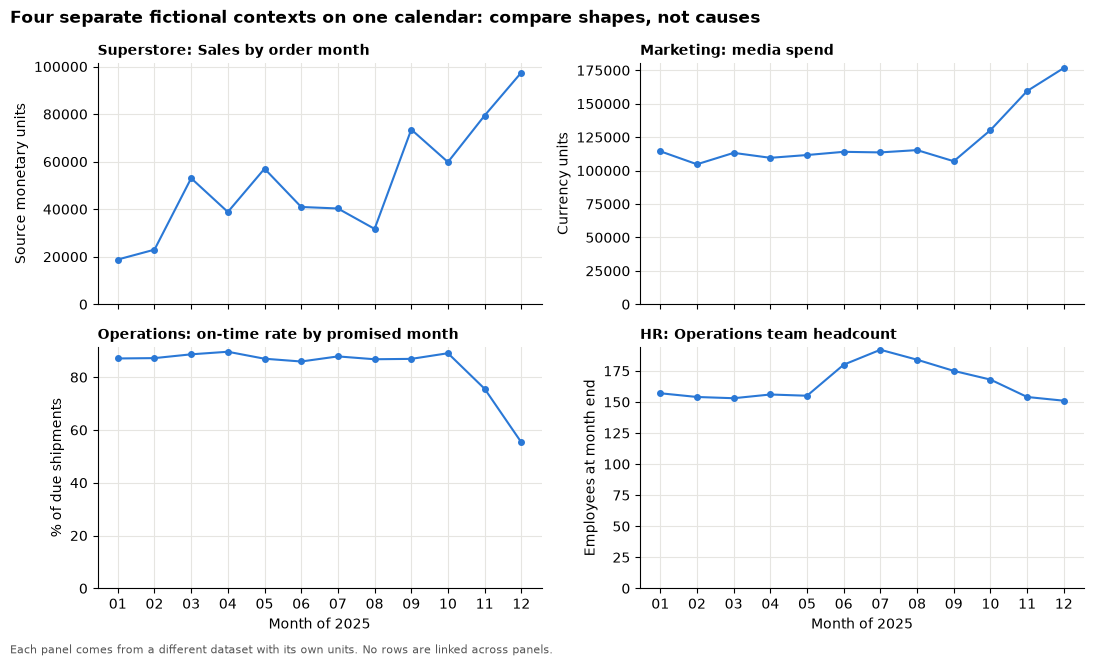

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
panels = [
    ("Retail Sales (source units)", "Superstore: Sales by order month", "Source monetary units", 1),
    ("Marketing spend (currency units)", "Marketing: media spend", "Currency units", 1),
    ("Operations on-time rate", "Operations: on-time rate by promised month", "% of due shipments", 100),
    ("HR Operations headcount (closing)", "HR: Operations team headcount", "Employees at month end", 1),
]
x = np.arange(12)
for ax, (col, title, ylabel, scale) in zip(axes.flat, panels):
    ax.plot(x, side_by_side[col] * scale, marker="o", markersize=4, color="#2a78d6")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, None)
for ax in axes[1]:
    ax.set_xticks(x, [m[5:] for m in side_by_side.index])
    ax.set_xlabel("Month of 2025")
fig.suptitle("Four separate fictional contexts on one calendar: compare shapes, not causes",
             fontweight="bold", x=0.01, ha="left")
fig.text(0.01, -0.01, "Each panel comes from a different dataset with its own units. No rows are linked across panels.",
         fontsize=8, color="#555555")
fig.tight_layout()
plt.show()

Each panel answers a question about **its own** context. Retail Sales and marketing spend both rise late in the year; the on-time rate falls at the end of the year; the Operations team grew in mid-year and then shrank.

> **Predict, then reveal**
>
> Compute the correlation between monthly marketing spend and the monthly on-time rate. These come from **different fictional organisations**. What value do you expect?

In [15]:
side_by_side.corr().round(2)

,Retail Sales (source units),Marketing spend (currency units),Operations on-time rate,HR Operations headcount (closing)
Retail Sales (source units),1.00,0.76,-0.72,-0.25
Marketing spend (currency units),0.76,1.00,-0.91,-0.34
Operations on-time rate,-0.72,-0.91,1.00,0.35
HR Operations headcount (closing),-0.25,-0.34,0.35,1.00


The correlations in the table above are strong, including between marketing spend and the on-time rate, which come from datasets that have **nothing to do with each other**. Why?

- Several series share a **calendar pattern**: activity builds towards the end of the year. Any two series with a year-end bump will correlate, whatever their source. This is a **common trend**, a kind of confounding from [Session 8](08_correlation_and_regression_lecture.md).
- There are only **12 points**. With so few, strong correlations appear easily by chance.
- No mechanism connects them: no shared orders, staff or shipments.

So **co-movement across separate contexts is not evidence of a link**. Within one real company you would still need a mechanism, shared keys and a design (such as an experiment) before claiming that one series drives another.

> **Check your understanding 3**
>
> A draft capstone says: "When marketing spend went up, deliveries got worse (correlation −0.9), so marketing overloaded the warehouse." Give three reasons this sentence cannot be supported with these datasets.

---

## Part 6: Trade-off analysis

The register says what is **true**. A decision also needs what **matters**. A simple, transparent tool is a **weighted scoring table**:

1. List the **options** (A to D from Part 2).
2. Choose a few **criteria** that matter to the decision-maker, and write down what a high score means.
3. **Score** each option on each criterion from 1 (poor) to 5 (strong), with a **reason** that points to the register.
4. Give each criterion a **weight** (weights add up to 1) and compute the weighted score.
5. Test whether the ranking **survives** reasonable changes in the weights.

| Criterion | 5 means | Evidence it rests on |
|---|---|---|
| **Size of problem** | Large gap affecting many customers or a lot of money | Register values |
| **Strength of evidence** | Clean contract, checks passed, few caveats | Register checks and limitations |
| **Cost (5 = cheap)** | Little money or effort to act | Judgement; ask the owner |
| **Speed to effect** | Results visible within the quarter | Judgement |
| **Urgency** | Waiting makes it clearly worse | Trend in the register period |

> **Scores are judgements, not data**
>
> The table makes judgement **visible** so others can disagree with a specific number. It does not make judgement objective. Always show the reasons next to the scores.

In [16]:
scores = pd.DataFrame({
    "size":     [5, 4, 3, 2],
    "evidence": [4, 3, 2, 5],
    "cost":     [3, 3, 5, 4],
    "speed":    [4, 2, 5, 3],
    "urgency":  [5, 4, 2, 2],
}, index=["A: carrier and peak capacity", "B: Operations retention", "C: marketing budget shift", "D: software contracts"])

reasons = {
    "A: carrier and peak capacity": "E2: large December drop on many shipments; clean due-population contract",
    "B: Operations retention": "E3: high turnover, but causes unknown and effect slow",
    "C: marketing budget shift": "E4: cheap and fast, but attribution is not incremental",
    "D: software contracts": "E5: well-measured overspend, but a small share of spend",
}

weights = pd.Series({"size": 0.30, "evidence": 0.25, "cost": 0.15, "speed": 0.15, "urgency": 0.15})
assert abs(weights.sum() - 1) < 1e-9, "weights must add up to 1"

result = scores.assign(weighted=scores @ weights, reason=pd.Series(reasons)).sort_values("weighted", ascending=False)
result

,size,evidence,cost,speed,urgency,weighted,reason
A: carrier and peak capacity,5,4,3,4,5,4.30,E2: large December drop on many shipments; cle...
B: Operations retention,4,3,3,2,4,3.30,"E3: high turnover, but causes unknown and effe..."
D: software contracts,2,5,4,3,2,3.20,"E5: well-measured overspend, but a small share..."
C: marketing budget shift,3,2,5,5,2,3.20,"E4: cheap and fast, but attribution is not inc..."


Option A has the highest weighted score with these weights. But someone in the room will say "evidence should count for more" or "cost is what really matters". Before you present a ranking, test it.

> **Predict, then reveal**
>
> If you give **cost** twice its weight (and scale the others down so the weights still add to 1), does option A stay first?

In [17]:
def rerank(scores, weights, criterion, factor):
    """Multiply one criterion's weight by `factor`, renormalise to 1, and return the winner and its margin."""
    w = weights.copy()
    w[criterion] *= factor
    w = w / w.sum()
    total = (scores @ w).sort_values(ascending=False)
    return {"criterion": criterion, "weight now": round(w[criterion], 2), "winner": total.index[0],
            "margin over 2nd": round(total.iloc[0] - total.iloc[1], 2)}


one_at_a_time = pd.DataFrame([rerank(scores, weights, c, f) for c in weights.index for f in (0.5, 2.0)])
one_at_a_time

,criterion,weight now,winner,margin over 2nd
0,size,0.18,A: carrier and peak capacity,0.76
1,size,0.46,A: carrier and peak capacity,1.00
2,evidence,0.14,A: carrier and peak capacity,0.97
3,evidence,0.40,A: carrier and peak capacity,0.68
4,cost,0.08,A: carrier and peak capacity,1.08
5,cost,0.26,A: carrier and peak capacity,0.70
6,speed,0.08,A: carrier and peak capacity,0.92
7,speed,0.26,A: carrier and peak capacity,0.83
8,urgency,0.08,A: carrier and peak capacity,0.95
9,urgency,0.26,A: carrier and peak capacity,1.00


The table above changes **one** weight at a time, halving or doubling it. A second, broader test draws thousands of **random** weight sets and counts how often each option comes first. The generator is **seeded**, so everyone gets the same result.

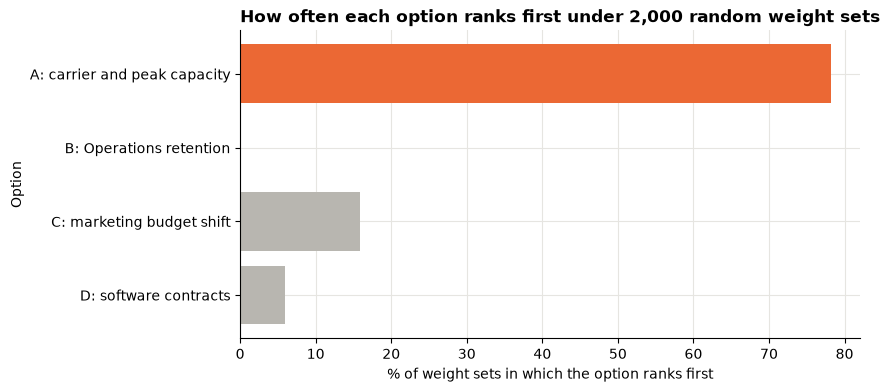

,ranked first
A: carrier and peak capacity,78%
B: Operations retention,0%
C: marketing budget shift,16%
D: software contracts,6%


In [18]:
rng = np.random.default_rng(seed=15)
random_weights = rng.dirichlet(np.ones(len(weights)), size=2000)    # 2,000 weight sets, each adding to 1
totals = scores.to_numpy() @ random_weights.T                       # one column of totals per weight set
winners = pd.Series(scores.index[totals.argmax(axis=0)])
share_first = winners.value_counts(normalize=True).reindex(scores.index, fill_value=0)

ax = plt.gca()
ax.barh(share_first.index, share_first * 100, color=["#eb6834"] + ["#b8b6b0"] * 3)
ax.invert_yaxis()
ax.set_title("How often each option ranks first under 2,000 random weight sets")
ax.set_xlabel("% of weight sets in which the option ranks first")
ax.set_ylabel("Option")
plt.show()
share_first.map("{:.0%}".format).to_frame("ranked first")

How to read the two tests:

- If the winner stays the same when you halve or double any single weight, and wins in most random weight sets, the recommendation is **robust to weighting**. Say so in one sentence.
- If the winner flips, the decision depends on **values**, not data. Show the decision-maker which weight matters and let them choose: "If cost matters most, D; otherwise A."
- Neither test checks the **scores** themselves. A wrong score is a wrong input, whatever the weights. Peer review (Part 8) is where scores get challenged.

> **Check your understanding 4**
>
> Option A wins in most random weight sets. A colleague says, "So A is the right decision with that probability." What is wrong with this reading?

---

## Part 7: The validation pack

The **validation pack** is what lets a reviewer trust your numbers without redoing the whole project. It has three parts:

| Part | Contents | Why |
|---|---|---|
| **Data versions** | Dataset name, file, SHA-256 checksum, rows, as-of date | Proves which exact data produced the numbers |
| **Reconciliations** | Totals and counts that must agree, written as `assert` checks | Catches joins, filters and dropped rows |
| **Reproducibility** | A notebook that runs from top to bottom in a fresh session, with fixed seeds and library versions | Anyone gets the same numbers |

The setup cells already checked each file's **SHA-256** when it was loaded: a mismatch would have printed a warning. The cell below records the versions explicitly, and adds a short **fingerprint** of each loaded table so you can tell later whether a table changed after loading.

In [19]:
def source_sha256(local_dir, url, name):
    """SHA-256 of a source file, read the same way as its setup cell reads it."""
    if local_dir:
        with open(os.path.join(local_dir, name), "rb") as f:
            return hashlib.sha256(f.read()).hexdigest()
    return hashlib.sha256(urllib.request.urlopen(url + name).read()).hexdigest()


def fingerprint(df):
    """First 12 characters of the SHA-256 of the table's CSV text: changes if any value changes."""
    return hashlib.sha256(df.to_csv(index=False).encode()).hexdigest()[:12]


versions = pd.DataFrame([
    ("Superstore", "sample_-_superstore.xls", EXPECTED_SHA256[:12], digest == EXPECTED_SHA256, len(orders), fingerprint(orders)),
    ("marketing-v1", "marketing_daily.csv", MARKETING_SHA256["marketing_daily.csv"][:12],
     source_sha256(MARKETING_DIR, MARKETING_URL, "marketing_daily.csv") == MARKETING_SHA256["marketing_daily.csv"],
     len(marketing), fingerprint(marketing)),
    ("finance-v1", "finance_actuals.csv", FINANCE_SHA256["finance_actuals.csv"][:12],
     source_sha256(FINANCE_DIR, FINANCE_URL, "finance_actuals.csv") == FINANCE_SHA256["finance_actuals.csv"],
     len(actuals), fingerprint(actuals)),
    ("finance-v1", "finance_budget.csv", FINANCE_SHA256["finance_budget.csv"][:12],
     source_sha256(FINANCE_DIR, FINANCE_URL, "finance_budget.csv") == FINANCE_SHA256["finance_budget.csv"],
     len(budget), fingerprint(budget)),
    ("operations-v1", "shipments.csv", OPERATIONS_SHA256["shipments.csv"][:12],
     source_sha256(OPERATIONS_DIR, OPERATIONS_URL, "shipments.csv") == OPERATIONS_SHA256["shipments.csv"],
     len(shipments), fingerprint(shipments)),
    ("hr-v1", "department_history.csv", HR_SHA256["department_history.csv"][:12],
     source_sha256(HR_DIR, HR_URL, "department_history.csv") == HR_SHA256["department_history.csv"],
     len(history), fingerprint(history)),
], columns=["dataset", "file", "sha256 (start)", "matches course version", "rows", "table fingerprint"])
versions

,dataset,file,sha256 (start),matches course version,rows,table fingerprint
0,Superstore,sample_-_superstore.xls,5045ed4fec49,True,6815,434ba08abf66
1,marketing-v1,marketing_daily.csv,1cbfc8e1c91a,True,2555,01c3bb8def10
2,finance-v1,finance_actuals.csv,3aeb2773990f,True,1378,42935e43755e
3,finance-v1,finance_budget.csv,238dbec8e7e8,True,432,d3ddff398ffb
4,operations-v1,shipments.csv,7b5c0860beb2,True,5893,7b5c0860beb2
5,hr-v1,department_history.csv,12e6524a7838,True,543,12e6524a7838


In the table above, `matches course version` recomputes each source file's checksum and compares it with the one written in its setup cell. The fingerprint is a second, quicker check you can rerun at the end of a long notebook. Next, the reconciliations. Each line is an `assert`, so a broken number stops the notebook instead of slipping into a briefing.

In [20]:
checks = {}

checks["Retail: monthly Sales add up to the 2025 total"] = np.isclose(
    retail_m["sales"].sum(), orders.loc[orders["order_date"].dt.year == 2025, "sales"].sum())
checks["Marketing: monthly spend adds up to the daily total"] = np.isclose(
    marketing_m["spend"].sum(), marketing["spend"].sum())
checks["Finance: aggregated cells keep every posting's amount"] = np.isclose(
    cells["actual"].sum(), actuals["amount"].sum())
checks["Finance: budget not multiplied by the join"] = np.isclose(
    cells["budget"].sum(), budget["budget"].sum())
populations = s["population"].value_counts()
checks["Operations: populations add back to all shipments"] = populations.sum() == len(shipments)
checks["Operations: monthly due counts add up to all due"] = operations_m["due"].sum() == populations["due"]
h = history.sort_values(["employee_id", "effective_from"])
dept_exits = (~h.duplicated("employee_id", keep="last") & h["effective_to"].between("2025-01-01", CUTOFF)).sum()
checks["HR: department exits add up to company exits"] = dept_exits == employees["exit_date"].between(
    "2025-01-01", CUTOFF).sum()

for name, ok in checks.items():
    assert ok, f"FAILED: {name}"
pd.Series({k: "PASS" for k in checks}).to_frame("result")

,result
Retail: monthly Sales add up to the 2025 total,PASS
Marketing: monthly spend adds up to the daily total,PASS
Finance: aggregated cells keep every posting's amount,PASS
Finance: budget not multiplied by the join,PASS
Operations: populations add back to all shipments,PASS
Operations: monthly due counts add up to all due,PASS
HR: department exits add up to company exits,PASS


In [21]:
print("Python ", platform.python_version())
print("pandas ", pd.__version__)
print("numpy  ", np.__version__)
print("Random seed used for the weight test: 15")

Python  3.12.13
pandas  2.2.3
numpy   2.5.4
Random seed used for the weight test: 15


Together, the three outputs above are the core of a validation pack. Add to them, for each domain:

1. **One hand check**: a small slice you computed another way (a filter you counted by eye, a fixture from the lectures).
2. **One corrected bug**: the wrong calculation, the right one, both numbers, and what the bug would have made a manager believe. Your lab portfolio already has one per domain.
3. **One sensitivity check** where a choice could matter: for example, excluding unknown promise dates, or using quarters instead of months for small teams.

> **Check your understanding 5**
>
> Your capstone notebook gives a different December on-time rate today than it did last week. Using the validation pack, list in order the three things you would check first.

---

## Part 8: Peer review protocol

A peer review is not a vote on whether the work is good. It is a **structured test** of the evidence, done by someone who did not build it.

| Step | Reviewer does | Author does |
|---|---|---|
| 1. **Read the decision** | Restate the decision and recommendation in one sentence | Confirm or correct the restatement |
| 2. **Pick one critical number** | Choose the number the recommendation depends on most and **recompute it** from the raw data, without looking at the author's code | Provide the register row and the data version |
| 3. **Test one competing explanation** | Name one other reason the pattern could appear, and look for evidence for or against it | Say whether the briefing already addresses it |
| 4. **Hunt for false links** | Check for joins across datasets, added revenues, mixed units and causal verbs | Fix or withdraw any claim that fails |
| 5. **Check the limitations** | Is every register row's limitation specific? Is anything important missing? | Add missing limits |
| 6. **Write the feedback** | One **strength**, one **critical issue**, one **next action** | Record the response in a revision log |

Rules that keep peer review useful:

- Be specific: "the December rate excludes pending shipments" helps; "check your numbers" does not.
- Critique the **evidence**, not the person.
- If the reviewer cannot reproduce the critical number, the claim is **not yet verified**, however good the chart looks.

---

## Part 9: Worked case: a draft capstone summary

Putting it together: the note below is written by code from the register and the trade-off table, so every number traces back to a checked calculation.

In [22]:
top = result.index[0]
print(
    f"Recommendation: fund option {top}.\n\n"
    f"Evidence: in the operations data, the on-time rate for shipments promised in December 2025 was "
    f"{dec['on_time_rate']:.0%} of {int(dec['due'])} due shipments, against {jan_oct_rate:.0%} for January to October "
    f"(register E2). In the HR data, the Operations team's 2025 turnover was {ops_turnover:.0%} of its average headcount "
    f"(E3). In the marketing data, {len(below_one)} of {len(campaigns)} campaigns returned less attributed revenue than "
    f"they cost (E4), and in the finance data Technology software ran {software_var_pct:+.0%} against budget (E5).\n\n"
    f"Trade-off: with the stated weights, option {top[0]} scores highest; it ranks first in {share_first[top]:.0%} of 2,000 random "
    f"weight sets.\n\n"
    f"Limits: the five datasets are separate fictional contexts, so no finding explains another. All findings are "
    f"descriptive; none shows a cause. Next evidence: delivery results by carrier for the next peak, and a review of "
    f"why December failed before committing the full budget."
)

Recommendation: fund option A: carrier and peak capacity.

Evidence: in the operations data, the on-time rate for shipments promised in December 2025 was 55% of 790 due shipments, against 88% for January to October (register E2). In the HR data, the Operations team's 2025 turnover was 54% of its average headcount (E3). In the marketing data, 2 of 7 campaigns returned less attributed revenue than they cost (E4), and in the finance data Technology software ran +17% against budget (E5).

Trade-off: with the stated weights, option A scores highest; it ranks first in 78% of 2,000 random weight sets.

Limits: the five datasets are separate fictional contexts, so no finding explains another. All findings are descriptive; none shows a cause. Next evidence: delivery results by carrier for the next peak, and a review of why December failed before committing the full budget.


Notice what the note does **not** say. It does not say that staff exits caused late deliveries, or that marketing caused either. It keeps each domain's finding inside its own context, compares the **options**, not the datasets, and ends with limits and the next evidence to collect.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| What must a capstone show? | One decision, three or more domains, all five in the portfolio | A tour of "insights" with no decision |
| How do I record evidence? | Evidence register: claim, source, metric, grain, period, value, check, limitation | Values typed by hand; blank limitations |
| How do I combine datasets? | Aggregate inside each dataset, then place side by side on a common calendar | Joining rows on month, order ID or department name |
| Can I add revenues across domains? | No: keep each measure in its own units and context | Adding attributed revenue to retail Sales |
| Do moving-together series show a link? | No: common trends and 12 points make correlation cheap | Causal words for co-movement |
| How do I weigh options? | Weighted scoring with reasons and a weight-sensitivity test | Hidden judgement presented as data |
| How does a reviewer trust it? | Validation pack: versions, reconciliations, reproducible notebook | "It looks right" as a check |

---

## Quiz

Answer these at the start of the next lecture, on **executive briefings**: presenting your capstone to a leadership team and handling their questions. Use common sense. Write short answers.

1. An executive gives you two minutes. What do you say in your **first** sentence?
2. Rewrite the slide title "On-time rate by month, 2025" as a title that states the "so what".
3. How would you tell a manager that December's on-time rate was low **and** how sure you are, in one sentence?
4. An executive asks, "How do you know?" What two things should your answer contain?
5. Why prepare an answer to "What would change your mind?" before you present?
6. Name one common way a good analysis gets lost in a presentation.

---

## Lab briefing

In the **Lab** you:

1. Load the five datasets and build an evidence register for three domains of your choice (defaults provided).
2. Write a validation checklist function that tests every register row.
3. Choose your capstone decision and draft its outline.
4. Build the side-by-side monthly view, with its caveat, and a trade-off table with a weight-sensitivity test.
5. Challenge: find and fix four problems in a flawed capstone draft.

Open the [Session 15 lab](15_capstone_studio_lab.md).